# Predicting a film's IMDb rating before release

**Question.** Using only what is known before a film comes out (title, year, runtime, genres, language and country), how well can we predict its IMDb rating, and where does the prediction fail?

**Data.** 133,884 films from IMDb, enriched with Wikipedia and OMDb. 115,560 have a rating and are used for modeling.

**Approach.** One feature function shared with the web app, all preprocessing inside scikit-learn pipelines, model selection by 10-fold cross-validation on the training set, and a single evaluation on a held-out test set. Then three questions about the result: which features matter, which films the model gets wrong and why, and whether it is equally accurate for different groups of films.

| | |
|---|---|
| Best model | Gradient Boosting |
| Test RMSE | 1.086 (always predicting the mean: 1.287) |
| Test R² | 0.288 |


In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sys.path.insert(0, "../src")
from features import prepare_data, parse_genres, NUMERIC, BINARY, CATEGORICAL, FEATURES

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("../data/movies_dataset.csv.gz")
FIG = Path("../images"); FIG.mkdir(exist_ok=True)
MODEL_OUT = Path("../app/model.joblib")

BLUE, ORANGE, GREEN, RED, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#2e9e6b", "#d1495b", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
})
rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))

## 1. The data

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
rated = raw[raw["averageRating"].notna()]          # keep the ORIGINAL index: it links every row back to its film
print(f"{len(raw):,} films | {len(rated):,} with a rating | {raw['tconst'].duplicated().sum()} duplicate IDs")
raw.isna().mean().mul(100).round(1).sort_values().rename("missing %").to_frame().T

133,884 films | 115,560 with a rating | 0 duplicate IDs


,tconst,primaryTitle,startYear,runtimeMinutes,genres,numVotes,lead_actors_ids,averageRating,plot,Language,Country,BoxOffice,budget
missing %,0.0,0.0,0.0,0.0,1.9,6.8,7.5,13.7,55.4,58.4,59.9,86.6,87.6


The columns `numVotes`, `BoxOffice` and `budget` are left out of the model: votes and box office accumulate only after release, and budget is missing for 88% of films. `plot` is missing for more than half the films and is not used.

One property of the target matters for everything that follows: an IMDb average based on a handful of votes is noisy.

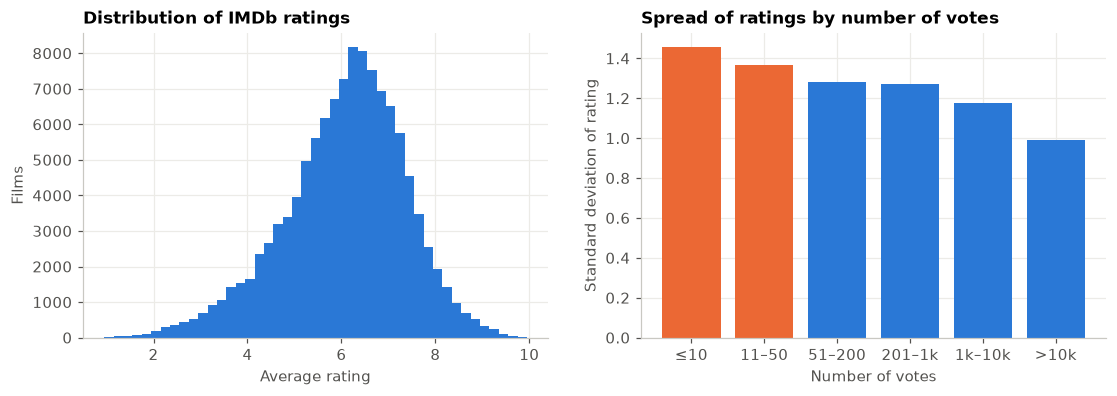

,films,mean,std,share of films
numVotes,,,,
≤10,3946,6.51,1.46,3.4%
11–50,23728,6.27,1.37,20.5%
51–200,28980,5.97,1.28,25.1%
201–1k,29545,5.74,1.27,25.6%
1k–10k,20466,6.13,1.18,17.7%
>10k,8895,6.61,0.99,7.7%


In [3]:
vote_bins = [-1, 10, 50, 200, 1_000, 10_000, np.inf]
vote_labels = ["≤10", "11–50", "51–200", "201–1k", "1k–10k", ">10k"]
rated_votes = pd.cut(rated["numVotes"], vote_bins, labels=vote_labels)
noise = rated.groupby(rated_votes, observed=True)["averageRating"].agg(films="size", mean="mean", std="std")
noise["share of films"] = noise["films"] / noise["films"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(rated["averageRating"], bins=np.arange(0.95, 10.1, 0.2), color=BLUE)
axes[0].set(title="Distribution of IMDb ratings", xlabel="Average rating", ylabel="Films")
axes[1].bar(noise.index.astype(str), noise["std"], color=[ORANGE if s > 1.3 else BLUE for s in noise["std"]])
axes[1].set(title="Spread of ratings by number of votes", xlabel="Number of votes", ylabel="Standard deviation of rating")
fig.savefig(FIG / "01_target_and_vote_noise.png"); plt.show()
noise.style.format({"mean": "{:.2f}", "std": "{:.2f}", "share of films": "{:.1%}"})

Ratings are roughly bell-shaped around 6.07. Films rated by 50 votes or fewer make up 24% of the data, and their ratings spread much more widely (standard deviation 1.46 for ≤10 votes against 0.99 for more than 10,000). Part of the error in any model here is irreducible noise from small audiences. Section 6 checks how much.

## 2. Features

All features come from `src/features.py`, the same function the web app calls, so the model sees identical inputs in training and in production.

| Group | Features | Why |
|---|---|---|
| Basics | `runtimeMinutes`, `movie_age` | Older films that are still rated tend to be the ones people remember; runtime separates shorts from epics |
| Genres | 20 genre flags, `num_genres` | Genres differ by more than two rating points on average (Documentary 7.2, Horror 4.9) |
| Genre pairs | Drama+Romance, Comedy+Drama, Horror+Thriller, Action+Adventure, Crime+Drama, Biography+Documentary | A combination can behave differently from its parts |
| Title | `title_words`, `is_sequel`, `has_subtitle` | Sequels average 5.6 against 6.1 for other films; films with long titles or a subtitle average higher |
| Interaction | `documentary_runtime` | Tests whether long documentaries are rated higher than short ones |
| Origin | `Language`, `Country`, `film_industry` | Different industries have different audiences on IMDb |

Compared with the first version, the genre list grew from 10 to 20, the genre-pair and title features are new, and `is_english` was removed because it duplicated the `Language = English` column created by one-hot encoding. Release years after 2025 are now treated as age 0 rather than as missing, so the web app handles upcoming films correctly.

In [4]:
X_all = prepare_data(rated)
y_all = rated["averageRating"]
meta = rated[["tconst", "primaryTitle", "startYear", "genres", "numVotes", "Country", "Language"]]
assert X_all.index.equals(meta.index)
print(X_all.shape)
X_all.head(3)

(115560, 36)


,runtimeMinutes,movie_age,num_genres,title_words,documentary_runtime,genre_Drama,genre_Comedy,genre_Romance,genre_Action,genre_Documentary,...,pair_Comedy_Drama,pair_Horror_Thriller,pair_Action_Adventure,pair_Crime_Drama,pair_Biography_Documentary,is_sequel,has_subtitle,Language,Country,film_industry
0,90.0,32.0,3,4,0.0,1,0,0,0,0,...,0,0,0,1,0,0,0,Spanish,Other,Other
1,86.0,1.0,1,3,0.0,1,0,0,0,0,...,0,0,0,0,0,0,0,NaN,NaN,Other
4,102.0,19.0,1,6,0.0,0,1,0,0,0,...,0,0,0,0,0,0,0,NaN,NaN,Other


In [5]:
genre_lists = rated["genres"].apply(parse_genres)
is_doc = X_all["genre_Documentary"] == 1
slope = lambda d: np.polyfit(d["runtimeMinutes"], d["averageRating"], 1)[0] * 60
d_all = rated[["runtimeMinutes", "averageRating"]].dropna()
d_doc = rated.loc[is_doc, ["runtimeMinutes", "averageRating"]].dropna()
seq = X_all["is_sequel"] == 1
summary = pd.DataFrame({
    "films": [seq.sum(), (~seq).sum()],
    "mean rating": [y_all[seq].mean(), y_all[~seq].mean()]}, index=["sequel", "not a sequel"])
print(f"Rating change per extra hour of runtime: all films {slope(d_all):+.2f} | documentaries {slope(d_doc):+.2f}")
display(summary.round(2))
decade = (rated["startYear"].where(rated["startYear"] >= 1900) // 10 * 10).astype("Int64")
by_decade = rated.groupby(decade).agg(films=("averageRating", "size"), mean_rating=("averageRating", "mean"),
                                      share_le50_votes=("numVotes", lambda v: (v <= 50).mean()))
by_decade.loc[1950:].style.format({"mean_rating": "{:.2f}", "share_le50_votes": "{:.0%}"})

Rating change per extra hour of runtime: all films +0.54 | documentaries +0.20


,films,mean rating
sequel,2010,5.64
not a sequel,113550,6.08


,films,mean_rating,share_le50_votes
startYear,,,
1950,4602,6.23,30%
1960,6208,6.17,32%
1970,7969,6.02,29%
1980,9631,6.00,26%
1990,10213,6.00,20%
2000,17555,6.08,19%
2010,33605,6.05,23%
2020,18405,6.06,23%


Two quick checks behind the feature choices. Sequels average 5.64 against 6.08 for other films. An extra hour of runtime goes with +0.54 rating points across all films but only +0.20 among documentaries. That second number matters for section 5. The decade table shows a gentle U-shape: films from the 1920s to 1960s average about 6.2 to 6.3, films from the 1970s to 1990s about 6.0.

## 3. Train/test split and pipelines

The split keeps the original row index, so every prediction can be traced back to its film by `tconst`. The first version reset the index after dropping unrated films and then looked titles up in the unfiltered table, which attached the wrong title, year and genres to almost every prediction. The assertion below guards against that.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
assert X_train.index.equals(y_train.index) and (meta.loc[X_train.index, "tconst"].values == rated.loc[X_train.index, "tconst"].values).all()
print(f"train {len(X_train):,} | test {len(X_test):,}")

def make_preprocessor(scale_all: bool) -> ColumnTransformer:
    """Linear models get every column standardised (so coefficients are comparable); trees get none."""
    scaler = [("scale", StandardScaler())] if scale_all else []
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median"))] + scaler), NUMERIC),
        ("bin", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=0))] + scaler), BINARY),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))] + scaler), CATEGORICAL),
    ], verbose_feature_names_out=False)

cv10 = KFold(n_splits=10, shuffle=True, random_state=SEED)

train 92,448 | test 23,112


Every imputer, scaler and encoder is fitted inside the pipeline, so in cross-validation it only ever sees the training folds. The test set is used once, in section 4.

In the first version only the numeric columns were standardised, while binary and one-hot columns stayed on a 0/1 scale. That made the Elastic Net coefficients incomparable across feature types. Here the linear model standardises every column.

## 4. Models

In [7]:
en_search = GridSearchCV(
    Pipeline([("prep", make_preprocessor(True)), ("model", ElasticNet(max_iter=5000, random_state=SEED))]),
    {"model__alpha": [0.0005, 0.002, 0.01, 0.05], "model__l1_ratio": [0.1, 0.5, 0.9]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
dt_search = GridSearchCV(
    Pipeline([("prep", make_preprocessor(False)), ("model", DecisionTreeRegressor(random_state=SEED))]),
    {"model__max_depth": [6, 8, 10, 12], "model__min_samples_leaf": [20, 50, 100]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
print("Elastic Net:", en_search.best_params_, "| Decision Tree:", dt_search.best_params_)

models = {
    "Mean baseline": Pipeline([("model", DummyRegressor())]),
    "Elastic Net": en_search.best_estimator_,
    "Decision Tree": dt_search.best_estimator_,
    "Random Forest": Pipeline([("prep", make_preprocessor(False)), ("model", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor(False)), ("model", HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.05, max_leaf_nodes=48, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED))]),
}
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv10, n_jobs=1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    cv_rows.append({"model": name, "CV RMSE": -s["test_rmse"].mean(), "± (sd)": s["test_rmse"].std(),
                    "CV MAE": -s["test_mae"].mean(), "CV R²": s["test_r2"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.style.format("{:.3f}")

Elastic Net: {'model__alpha': 0.0005, 'model__l1_ratio': 0.1} | Decision Tree: {'model__max_depth': 12, 'model__min_samples_leaf': 100}


,CV RMSE,± (sd),CV MAE,CV R²
model,,,,
Mean baseline,1.294,0.012,1.015,-0.000
Elastic Net,1.126,0.015,0.860,0.244
Decision Tree,1.114,0.016,0.849,0.260
Random Forest,1.093,0.016,0.832,0.286
Gradient Boosting,1.088,0.017,0.827,0.293


Best model by CV RMSE: Gradient Boosting


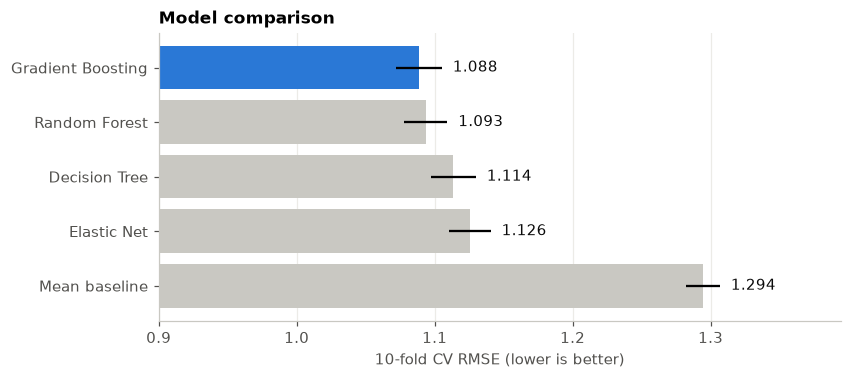

,CV RMSE,± (sd),CV MAE,CV R²,Test RMSE,Test MAE,Test R²,gap (test − CV)
model,,,,,,,,
Mean baseline,1.294,0.012,1.015,-0.000,1.287,1.009,-0.000,-0.008
Elastic Net,1.126,0.015,0.860,0.244,1.122,0.858,0.240,-0.004
Decision Tree,1.114,0.016,0.849,0.260,1.115,0.848,0.250,0.001
Random Forest,1.093,0.016,0.832,0.286,1.089,0.830,0.283,-0.004
Gradient Boosting,1.088,0.017,0.827,0.293,1.086,0.825,0.288,-0.003


In [8]:
test_rows, fitted = [], {}
for name, model in models.items():
    fitted[name] = model.fit(X_train, y_train)
    p = fitted[name].predict(X_test)
    test_rows.append({"model": name, "Test RMSE": rmse(y_test, p), "Test MAE": mean_absolute_error(y_test, p), "Test R²": r2_score(y_test, p)})
results = cv_table.join(pd.DataFrame(test_rows).set_index("model"))
results["gap (test − CV)"] = results["Test RMSE"] - results["CV RMSE"]
best_name = results.drop("Mean baseline")["CV RMSE"].idxmin()
best = fitted[best_name]
print("Best model by CV RMSE:", best_name)

fig, ax = plt.subplots(figsize=(8, 3.4))
order = results.sort_values("CV RMSE", ascending=False)
ax.barh(order.index, order["CV RMSE"], xerr=order["± (sd)"], color=[BLUE if n == best_name else GREY for n in order.index])
for i, (v, sd) in enumerate(zip(order["CV RMSE"], order["± (sd)"])):
    ax.text(v + sd + 0.008, i, f"{v:.3f}", va="center", color=INK)
ax.set(xlim=(0.9, order["CV RMSE"].max() + 0.1), xlabel="10-fold CV RMSE (lower is better)", title="Model comparison")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "02_model_comparison.png"); plt.show()
results.style.format("{:.3f}")

**Reading.** Gradient Boosting is best by a small margin, with a cross-validated RMSE of 1.088 against 1.294 for always predicting the mean, a 15.9% reduction. The Random Forest is close behind (1.093). The gap between the two is smaller than the fold-to-fold spread, so they are practically tied. Boosting is used in the app because its file is 0.6 MB, against 153 MB for the Random Forest in the first version. The single tree and the linear model trail. Test scores are within 0.008 of the CV scores for every model, which is what we expect when nothing from the test set leaks into training.

An R² of about 0.29 is modest, and that is the honest result: from title, year, runtime, genres and origin alone, most of what makes a film good or bad is invisible. The gain over the first version (1.099) comes from the added features and the boosting model.

### What did each feature group add?

To separate the effect of the new features from the effect of the new model, the same gradient-boosting model is refit with feature groups added one at a time (5-fold CV on the training set).

In [9]:
from features import GENRES, GENRE_PAIRS
OLD_GENRES = ["Drama", "Comedy", "Documentary", "Romance", "Action", "Crime", "Thriller", "Horror", "Adventure", "Family"]
groups = {
    "First-version features": (["runtimeMinutes", "movie_age", "num_genres", "documentary_runtime"], [f"genre_{g}" for g in OLD_GENRES]),
    "+ 10 more genres and genre pairs": (["runtimeMinutes", "movie_age", "num_genres", "documentary_runtime"],
                                         [f"genre_{g}" for g in GENRES] + [f"pair_{a}_{b}" for a, b in GENRE_PAIRS]),
    "+ title features (final)": (NUMERIC, BINARY),
}
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
ablation = {}
for label, (num, binary) in groups.items():
    prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                              ("bin", SimpleImputer(strategy="constant", fill_value=0), binary),
                              ("cat", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                                ("o", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL)])
    pipe = Pipeline([("prep", prep), ("model", models["Gradient Boosting"].named_steps["model"])])
    ablation[label] = -cross_validate(pipe, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error")["test_score"].mean()
no_origin = Pipeline([("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), NUMERIC),
                                                  ("bin", SimpleImputer(strategy="constant", fill_value=0), BINARY)])),
                      ("model", models["Gradient Boosting"].named_steps["model"])])
origin_ablation = -cross_validate(no_origin, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error")["test_score"].mean() - ablation["+ title features (final)"]
print(f"Without Language, Country and film_industry: CV RMSE changes by {origin_ablation:+.4f}")
ablation = pd.Series(ablation, name="CV RMSE").to_frame()
ablation["change"] = ablation["CV RMSE"].diff()
ablation.style.format("{:.4f}", na_rep="")

Without Language, Country and film_industry: CV RMSE changes by +0.0113


,CV RMSE,change
First-version features,1.1002,
+ 10 more genres and genre pairs,1.0910,-0.0092
+ title features (final),1.0893,-0.0017


Each group helps, and the gains are small: CV RMSE falls by 0.009 with the extra genres and pairs and by another 0.002 with the title features. That fits the picture above. The available information is thin, and better features shift the error by hundredths, not tenths.

A check on one of the inputs: `Language` and `Country` are missing for about 60% of films because no Wikipedia or OMDb page was found. Missingness is not random. Films without a page have a median of 111 votes against 461 for the rest, so it partly reflects how popular a film became after release. Dropping the three origin columns raises CV RMSE by 0.011, about as much as the extra genres add and small next to the 0.21 the model gains over the baseline. The origin columns help, but the model does not depend on them.

## 5. What drives the predictions

Three views, because each method has a known bias:

- **Elastic Net coefficients**, on fully standardised features: the effect of one standard deviation of each feature, holding the others fixed.
- **Impurity importance (MDI)** from the tree models: how much each feature reduced error inside the trees. MDI favours continuous features, which offer many more split points than a 0/1 flag.
- **Permutation importance** on held-out data, for the Random Forest and the boosting model: how much test error rises when one raw feature is shuffled. This is the fairest comparison across models, and it treats a categorical feature as one unit rather than as separate one-hot columns.

Boosting, documentary flag + interaction shuffled together: +0.119 RMSE


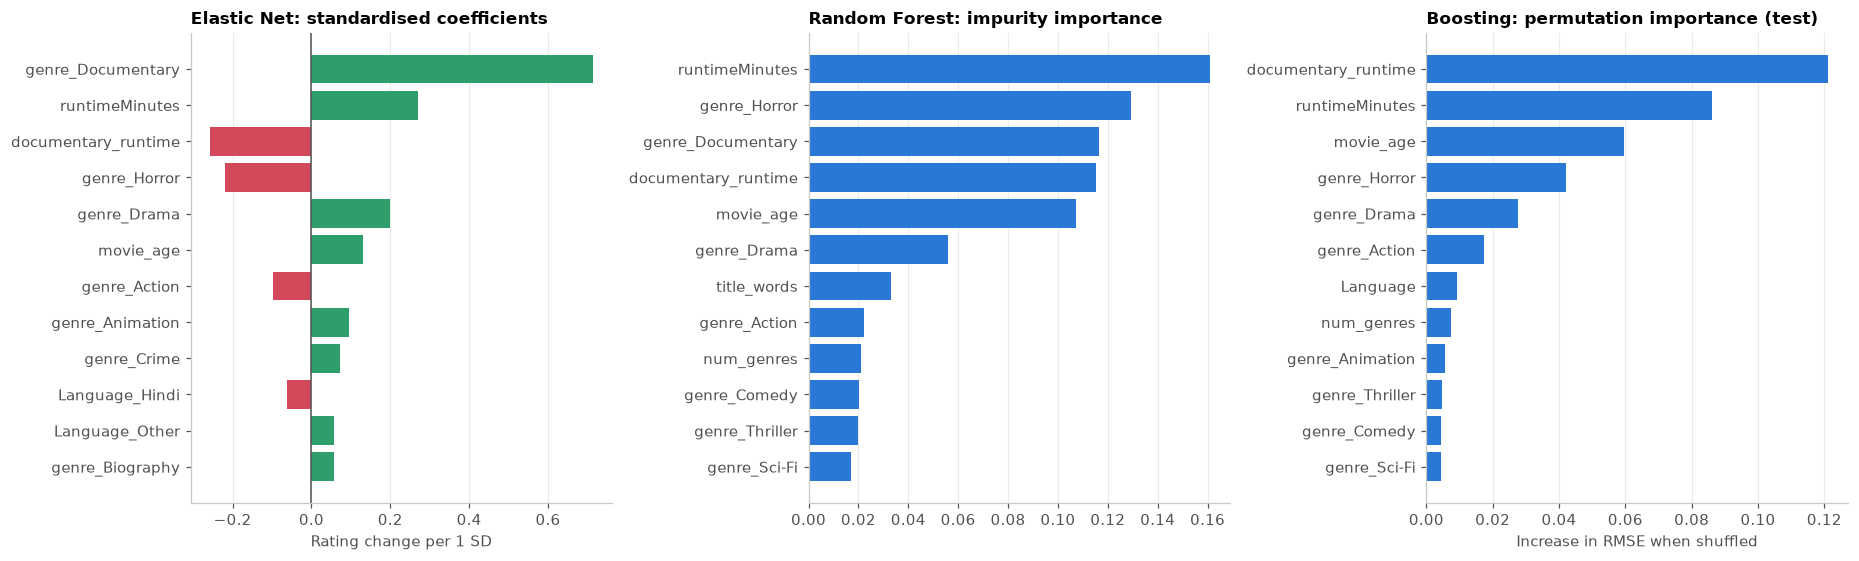

,EN |coef| rank,DT MDI rank,RF MDI rank
runtimeMinutes,2,3,1
genre_Horror,4,2,2
genre_Documentary,1,1,3
documentary_runtime,3,18,4
movie_age,6,4,5
genre_Drama,5,5,6
title_words,24,14,7
genre_Action,7,6,8
num_genres,18,8,9
genre_Comedy,22,11,10


In [10]:
names = lambda pipe: list(pipe.named_steps["prep"].get_feature_names_out())
en = fitted["Elastic Net"]; dt = fitted["Decision Tree"]; rf = fitted["Random Forest"]; gb = fitted["Gradient Boosting"]
en_coef = pd.Series(en.named_steps["model"].coef_, index=names(en))
rf_mdi = pd.Series(rf.named_steps["model"].feature_importances_, index=names(rf))
dt_mdi = pd.Series(dt.named_steps["model"].feature_importances_, index=names(dt))

sample = X_test.sample(8000, random_state=SEED)
perm = {}
for name in ["Random Forest", "Gradient Boosting"]:
    pi = permutation_importance(fitted[name], sample, y_test.loc[sample.index], n_repeats=5,
                                scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1)
    perm[name] = pd.Series(pi.importances_mean, index=sample.columns)
perm = pd.DataFrame(perm).sort_values("Gradient Boosting", ascending=False)

def grouped_permutation(model, X, y, cols, repeats=5):
    """Shuffle several columns together (same row order) and measure the rise in RMSE."""
    base, rises = rmse(y, model.predict(X)), []
    for k in range(repeats):
        Xp = X.copy(); order = np.random.default_rng(SEED + k).permutation(len(X))
        Xp[cols] = X[cols].values[order]
        rises.append(rmse(y, model.predict(Xp)) - base)
    return float(np.mean(rises))
doc_group = grouped_permutation(gb, sample, y_test.loc[sample.index], ["genre_Documentary", "documentary_runtime"])
print(f"Boosting, documentary flag + interaction shuffled together: +{doc_group:.3f} RMSE")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
top = en_coef.reindex(en_coef.abs().sort_values(ascending=False).index[:12])[::-1]
axes[0].barh(top.index, top.values, color=[GREEN if v > 0 else RED for v in top.values])
axes[0].axvline(0, color=MUTED, lw=1); axes[0].set(title="Elastic Net: standardised coefficients", xlabel="Rating change per 1 SD")
for ax, s, t in [(axes[1], rf_mdi, "Random Forest: impurity importance"), (axes[2], perm["Gradient Boosting"], "Boosting: permutation importance (test)")]:
    s = s.sort_values(ascending=False)[:12][::-1]
    ax.barh(s.index, s.values, color=BLUE); ax.set(title=t)
axes[2].set_xlabel("Increase in RMSE when shuffled")
for ax in axes: ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "03_feature_importance.png"); plt.show()

pd.DataFrame({"EN |coef| rank": en_coef.abs().rank(ascending=False),
              "DT MDI rank": dt_mdi.rank(ascending=False),
              "RF MDI rank": rf_mdi.rank(ascending=False)}).sort_values("RF MDI rank").head(10).astype(int)

In [11]:
perm.head(10).style.format("{:.4f}").set_caption("Permutation importance: rise in test RMSE when the feature is shuffled")

,Random Forest,Gradient Boosting
documentary_runtime,0.0269,0.1211
runtimeMinutes,0.0620,0.0860
movie_age,0.0358,0.0596
genre_Horror,0.0393,0.0422
genre_Drama,0.0221,0.0276
genre_Action,0.0129,0.0174
Language,0.0085,0.0094
num_genres,0.0061,0.0074
genre_Animation,0.0026,0.0058
genre_Thriller,0.0057,0.0049


**Why the models disagree.** The linear model and the single tree put genre flags at the top, while the Random Forest's impurity ranking is led by runtime, age and title length. These are different questions with different biases, not a contradiction:

- In the **Elastic Net**, a coefficient is the effect of one standard deviation. `genre_Documentary` moves the rating by +0.71 and `genre_Horror` by -0.22, a large shift for a single flag. Age has a U-shaped effect (section 2), and a straight line captures only part of it, so its coefficient looks small.
- The **Decision Tree** has few splits to spend, so it chooses the ones that separate the most films at once. The documentary split is the single biggest drop in error, so it comes first.
- The **Random Forest** with `max_features="sqrt"` often cannot use the strongest feature at a split, and its many deep trees keep splitting continuous columns at new thresholds. MDI credits every one of those splits, so continuous features accumulate importance even when each split adds little.

Permutation importance on unseen data gives a cleaner ranking. Shuffling runtime raises test RMSE by 0.086, age by 0.060 and the Horror flag by 0.042. The documentary flag on its own shows 0.000, but only because `documentary_runtime` carries the same information: the interaction is positive exactly when the film is a documentary. Shuffling the two together raises RMSE by 0.119, the largest effect of all. This is a known limit of permutation importance: correlated features share credit, so related columns have to be measured as a group.

The MDI bias is visible too. `title_words` is 7th in the Random Forest's impurity ranking, yet shuffling it raises test RMSE by only 0.002. Its many distinct values give the trees plenty of split points without adding much predictive power.

**The documentary interaction.** We created `documentary_runtime` expecting long documentaries to rate higher, yet its Elastic Net coefficient is -0.26. The model already has a general runtime effect (+0.54 points per hour) and a documentary flag. The interaction term measures how much the runtime slope for documentaries differs from the general slope. Among documentaries the slope is only +0.20 per hour, so the correction is negative. Long documentaries are rated slightly higher than short ones, but runtime matters less for them than for other films. The hypothesis was half right.

## 6. Error analysis

Out-of-fold predictions on the training set: each film is predicted by a model that never saw it. Titles and other details are looked up by index, and the check below confirms that every row is attached to the right film.

In [12]:
oof = pd.Series(cross_val_predict(best, X_train, y_train, cv=cv10, n_jobs=1), index=X_train.index)
err = meta.loc[X_train.index].copy()
err["actual"] = y_train; err["predicted"] = oof; err["residual"] = oof - y_train
assert (err["actual"] == rated.loc[err.index, "averageRating"]).all()
err["votes"] = pd.cut(err["numVotes"], vote_bins, labels=vote_labels)
print(f"OOF RMSE {rmse(err.actual, err.predicted):.3f} | predictions range {err.predicted.min():.1f}–{err.predicted.max():.1f} "
      f"(sd {err.predicted.std():.2f}) vs actual 1.0–10.0 (sd {err.actual.std():.2f})")

show = ["tconst", "primaryTitle", "startYear", "genres", "numVotes", "actual", "predicted", "residual"]
fmt = {"startYear": "{:.0f}", "numVotes": "{:,.0f}", "actual": "{:.1f}", "predicted": "{:.2f}", "residual": "{:+.2f}"}
display(err.nlargest(8, "residual")[show].style.format(fmt).hide(axis="index").set_caption("Largest over-predictions"))
display(err.nsmallest(8, "residual")[show].style.format(fmt).hide(axis="index").set_caption("Largest under-predictions"))

OOF RMSE 1.089 | predictions range 3.2–8.8 (sd 0.69) vs actual 1.0–10.0 (sd 1.29)


tconst,primaryTitle,startYear,genres,numVotes,actual,predicted,residual
tt28870073,Kurz,2023,Documentary,547,1.2,7.13,+5.93
tt11536660,At the Back of the Screen,2020,"Documentary,Drama",47,1.5,7.40,+5.90
tt6748034,Tribalism Is Killing Us,2019,['Documentary'],221,1.3,7.15,+5.85
tt1537218,Brush with Life: The Art of Being Edward Biberman,2007,['Documentary'],103,1.5,7.27,+5.77
tt1538949,Play in the Gray,2009,"Biography,Comedy,Documentary",180,1.3,7.06,+5.76
tt1615051,Obama in NC: The Path to History,2010,['Documentary'],17,1.5,7.23,+5.73
tt1702443,Justin Bieber: Never Say Never,2011,"Documentary,Music","76,601",1.7,7.35,+5.65
tt6096958,Kids Against the Sorcerers,2016,"Adventure,Animation,Drama",582,1.1,6.74,+5.64


tconst,primaryTitle,startYear,genres,numVotes,actual,predicted,residual
tt2379727,Bukunja Tekunja Mitti: The Cannibals,2012,"['Action', 'Horror']",68,9.1,4.44,-4.66
tt1684589,Son-nim-1 Cheo-beon-jjae I-ya-gi,2011,"Horror,Thriller",98,9.1,4.46,-4.64
tt6039316,Oscuro by Rene Potter,2016,['Horror'],26,8.6,4.08,-4.52
tt28115122,Justicia Implacable,2023,"Action,Drama,Horror",26,9.5,5.12,-4.38
tt39000499,Under Reflex,2024,"['Action', 'Comedy', 'Drama']",9,9.4,5.04,-4.36
tt26699418,Avengers: Doom of the World,2023,"Action,Adventure",40,8.9,4.58,-4.32
tt34657012,Gostya iz kosmosa,2024,"Adventure,Sci-Fi",8,8.7,4.42,-4.28
tt4009466,Of Sound Mind,2015,"['Romance', 'Thriller']",12,9.6,5.36,-4.24


Top 100 over-predictions: 28% documentaries (vs 11% of all films), median 186 votes
Top 100 under-predictions: 52% horror or action, median 24 votes (all films: 210)
Films with ≤50 votes: 24% of the data but 42% of the 500 largest errors


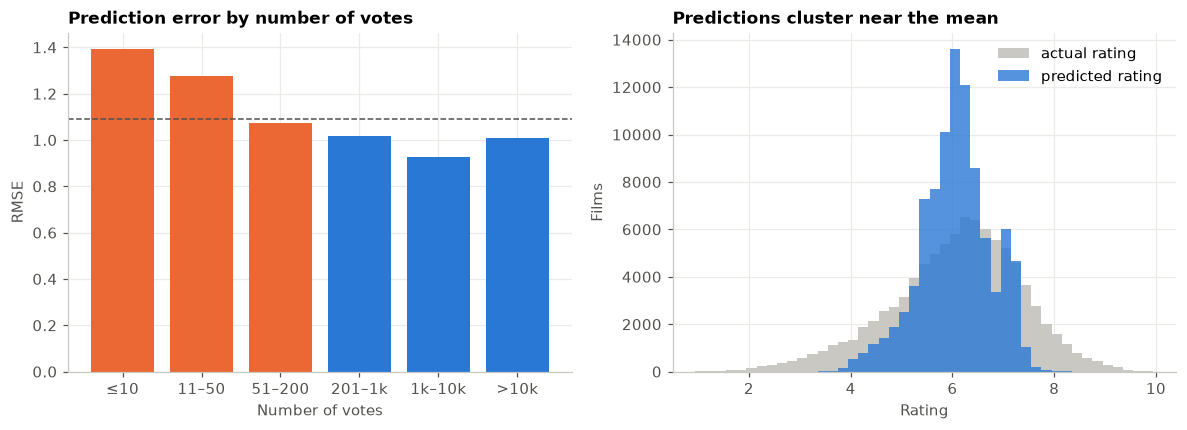

,films,share,RMSE,mean actual,mean predicted
votes,,,,,
≤10,"3,174",3.4%,1.393,6.53,6.36
11–50,"18,987",20.5%,1.277,6.28,6.16
51–200,"23,253",25.2%,1.074,5.97,6.07
201–1k,"23,585",25.5%,1.017,5.74,6.00
1k–10k,"16,381",17.7%,0.925,6.12,6.02
>10k,"7,068",7.6%,1.010,6.62,6.06


In [13]:
by_votes = err.groupby("votes", observed=True).apply(lambda g: pd.Series({
    "films": len(g), "share": len(g) / len(err), "RMSE": rmse(g.actual, g.predicted),
    "mean actual": g.actual.mean(), "mean predicted": g.predicted.mean()}))
worst = err.loc[err.residual.abs().nlargest(500).index]
share_worst_le50 = (worst.numVotes <= 50).mean(); share_all_le50 = (err.numVotes <= 50).mean()
top_over, top_under = err.nlargest(100, "residual"), err.nsmallest(100, "residual")
doc_share_over = top_over.genres.apply(lambda g: "Documentary" in parse_genres(g)).mean()
doc_share_all = (X_train.loc[err.index, "genre_Documentary"] == 1).mean()
horror_action_under = top_under.genres.apply(lambda g: bool({"Horror", "Action"} & set(parse_genres(g)))).mean()
print(f"Top 100 over-predictions: {doc_share_over:.0%} documentaries (vs {doc_share_all:.0%} of all films), median {top_over.numVotes.median():.0f} votes")
print(f"Top 100 under-predictions: {horror_action_under:.0%} horror or action, median {top_under.numVotes.median():.0f} votes (all films: {err.numVotes.median():.0f})")
print(f"Films with ≤50 votes: {share_all_le50:.0%} of the data but {share_worst_le50:.0%} of the 500 largest errors")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_votes.index.astype(str), by_votes["RMSE"], color=[ORANGE if v > by_votes.RMSE.median() else BLUE for v in by_votes.RMSE])
axes[0].axhline(rmse(err.actual, err.predicted), color=MUTED, ls="--", lw=1)
axes[0].set(title="Prediction error by number of votes", xlabel="Number of votes", ylabel="RMSE")
bins = np.arange(0.95, 10.1, 0.2)
axes[1].hist(err.actual, bins=bins, color=GREY, label="actual rating")
axes[1].hist(err.predicted, bins=bins, color=BLUE, alpha=0.8, label="predicted rating")
axes[1].set(title="Predictions cluster near the mean", xlabel="Rating", ylabel="Films"); axes[1].legend(frameon=False)
fig.savefig(FIG / "04_error_by_votes.png"); plt.show()
by_votes.style.format({"films": "{:,.0f}", "share": "{:.1%}", "RMSE": "{:.3f}", "mean actual": "{:.2f}", "mean predicted": "{:.2f}"})

**Two patterns, both measured.**

1. **The model shrinks toward the middle.** Predictions span 3.2 to 8.8 with a standard deviation of 0.69, against 1.29 for actual ratings. With weak features, predicting close to the mean is the error-minimising choice. Every film rated near 1 is therefore over-predicted, and every film rated near 9 or 10 is under-predicted.
2. **Small audiences cause many of the biggest misses.** Films with 50 votes or fewer are 24% of the training data but 42% of the 500 largest errors. RMSE is 1.39 for films with up to 10 votes and 1.01 for films with more than 10,000.
3. **The two directions have different causes.** The 100 largest under-predictions have a median of only 24 votes, and 52% are horror or action films. These are tiny audiences giving a 9 to a genre that usually gets a 5. The 100 largest over-predictions have a median of 186 votes, close to the 210 of all films, so they are not a small-sample effect. They are films rated far below what their genre suggests, and 28% of them are documentaries, against 11% of all films. The model has learned that documentaries score about 7 and has nothing to tell a poorly received documentary from a good one.

### Five films, checked against the data

In [14]:
famous = err[err.numVotes > 50_000]
cases = pd.concat([
    err.nlargest(1, "residual").assign(case="Largest over-prediction"),
    err.nsmallest(1, "residual").assign(case="Largest under-prediction"),
    famous.nlargest(1, "residual").assign(case="Well-known film, over-predicted"),
    famous.nsmallest(1, "residual").assign(case="Well-known film, under-predicted"),
])
ant = rated[rated.primaryTitle == "The Ant Bully"].index
ant_row = meta.loc[ant].assign(actual=y_all.loc[ant], case="Film flagged in the first version")
ant_row["predicted"] = oof.loc[ant] if ant[0] in oof.index else best.predict(X_all.loc[ant])  # out-of-fold if in train, else test prediction
ant_row["residual"] = ant_row["predicted"] - ant_row["actual"]
cases = pd.concat([cases, ant_row])
cases["IMDb page"] = "https://www.imdb.com/title/" + cases["tconst"] + "/"
cases[["case", "primaryTitle", "startYear", "genres", "numVotes", "actual", "predicted", "residual", "IMDb page"]].style.format(fmt).hide(axis="index")

case,primaryTitle,startYear,genres,numVotes,actual,predicted,residual,IMDb page
Largest over-prediction,Kurz,2023,Documentary,547,1.2,7.13,+5.93,https://www.imdb.com/title/tt28870073/
Largest under-prediction,Bukunja Tekunja Mitti: The Cannibals,2012,"['Action', 'Horror']",68,9.1,4.44,-4.66,https://www.imdb.com/title/tt2379727/
"Well-known film, over-predicted",Justin Bieber: Never Say Never,2011,"Documentary,Music","76,601",1.7,7.35,+5.65,https://www.imdb.com/title/tt1702443/
"Well-known film, under-predicted",Evil Dead II,1987,"['Comedy', 'Horror']","195,994",7.7,4.61,-3.09,https://www.imdb.com/title/tt0092991/
Film flagged in the first version,The Ant Bully,2006,"['Adventure', 'Animation', 'Comedy']","44,271",5.8,6.10,+0.30,https://www.imdb.com/title/tt0429589/


- **Kurz** (2023, documentary, 547 votes) is rated 1.2 and predicted 7.1. Every feature says "documentary", the genre with the highest average, and nothing in the features can explain a rating this low from several hundred voters.
- **Bukunja Tekunja Mitti: The Cannibals** (2012, action and horror, 68 votes) is rated 9.1 and predicted 4.4. Horror pulls the prediction down (the genre averages 4.9), and a 9.1 from 68 voters is the small-audience pattern above.
- **Justin Bieber: Never Say Never** (2011, music documentary, 76,601 votes) is rated 1.7 and predicted 7.4. With this many votes the rating is not noise. The film became a well-known target of mass low ratings on IMDb, a reaction to the artist rather than to anything a pre-release feature could capture.
- **Evil Dead II** (1987, comedy and horror, 195,994 votes) is rated 7.7 and predicted 4.6. Comedy-horror usually scores low, and a cult classic looks the same as any other comedy-horror on paper. Quality is simply not in these features.

The first version reported The Ant Bully with a rating of 9.5 and suggested rating manipulation. Its actual rating in the data is 5.8, from 44,271 votes, and the model predicts 6.10. The 9.5 belonged to a different film, attached by the indexing bug. Every case in this table now carries its IMDb ID, so anyone can check it against the source.

## 7. Is the model equally accurate for every group?

RMSE for each slice on the out-of-fold predictions, with a 95% bootstrap interval. A low RMSE can simply mean that ratings in a group vary little, so the table also shows **relative RMSE**: the slice's RMSE divided by the spread of actual ratings in that slice. A value of 1.0 means the model does no better than guessing the group's average; lower is better.

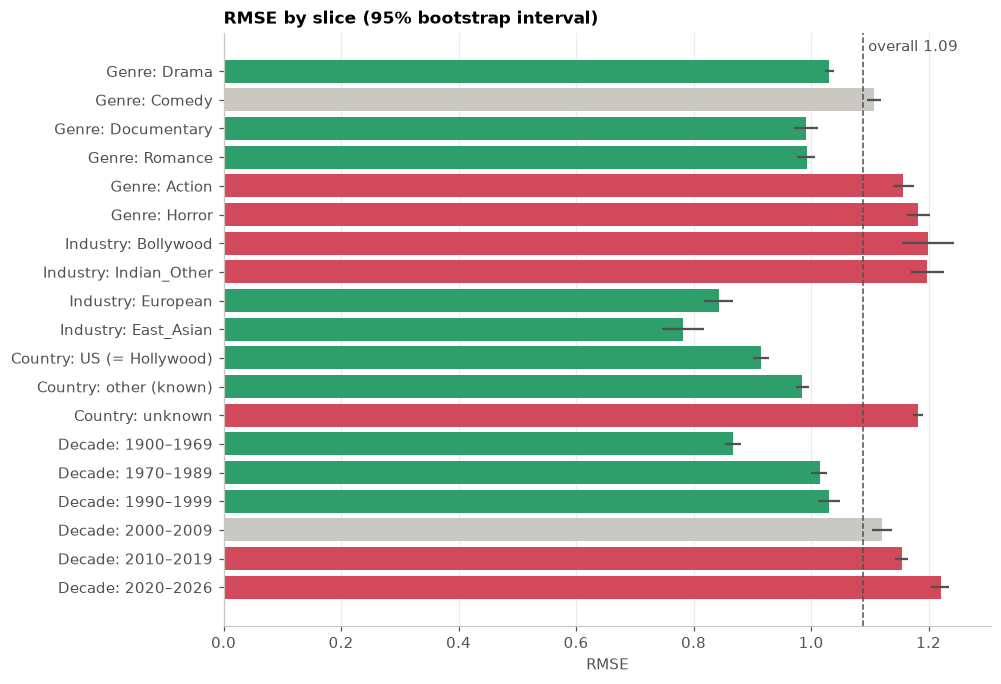

,films,RMSE,95% CI low,95% CI high,rating sd,relative RMSE
slice,,,,,,
Genre: Drama,"46,734",1.030,1.023,1.040,1.13,0.91
Genre: Comedy,"26,777",1.106,1.096,1.119,1.21,0.92
Genre: Documentary,"10,400",0.991,0.971,1.012,1.01,0.98
Genre: Romance,"12,540",0.994,0.977,1.007,1.07,0.93
Genre: Action,"11,110",1.157,1.139,1.174,1.33,0.87
Genre: Horror,"7,995",1.183,1.162,1.202,1.32,0.89
Industry: Bollywood,"1,788",1.200,1.155,1.244,1.32,0.91
Industry: Indian_Other,"3,679",1.198,1.171,1.226,1.32,0.91
Industry: European,"3,753",0.843,0.818,0.868,0.98,0.86


In [15]:
rng = np.random.default_rng(SEED)
def slice_stats(mask, label):
    g = err[mask]
    a, p = g.actual.values, g.predicted.values
    boot = [rmse(a[i], p[i]) for i in (rng.integers(0, len(g), len(g)) for _ in range(300))]
    return {"slice": label, "films": len(g), "RMSE": rmse(a, p), "95% CI low": np.percentile(boot, 2.5),
            "95% CI high": np.percentile(boot, 97.5), "rating sd": a.std(), "relative RMSE": rmse(a, p) / a.std()}

Xtr = X_train.loc[err.index]
rows = [slice_stats(Xtr[f"genre_{g}"] == 1, f"Genre: {g}") for g in ["Drama", "Comedy", "Documentary", "Romance", "Action", "Horror"]]
rows += [slice_stats(Xtr["film_industry"] == i, f"Industry: {i}") for i in ["Bollywood", "Indian_Other", "European", "East_Asian"]]
rows += [slice_stats(err.Country == "United States", "Country: US (= Hollywood)"), slice_stats(err.Country.notna() & (err.Country != "United States"), "Country: other (known)"),
         slice_stats(err.Country.isna() | (err.Country == "Not Found"), "Country: unknown")]
for lo, hi in [(1900, 1969), (1970, 1989), (1990, 1999), (2000, 2009), (2010, 2019), (2020, 2026)]:
    rows.append(slice_stats(err.startYear.between(lo, hi), f"Decade: {lo}–{hi}"))
fair = pd.DataFrame(rows).set_index("slice")
overall = rmse(err.actual, err.predicted)

fig, ax = plt.subplots(figsize=(9, 7))
f = fair.iloc[::-1]
colors = [GREEN if v < overall * 0.95 else RED if v > overall * 1.05 else GREY for v in f.RMSE]
ax.barh(f.index, f.RMSE, xerr=[f.RMSE - f["95% CI low"], f["95% CI high"] - f.RMSE], color=colors, ecolor=MUTED)
ax.axvline(overall, color=MUTED, ls="--", lw=1); ax.text(overall, len(f) - 0.3, f" overall {overall:.2f}", color=MUTED)
ax.set(title="RMSE by slice (95% bootstrap interval)", xlabel="RMSE"); ax.grid(axis="y", visible=False)
fig.savefig(FIG / "05_fairness_slices.png"); plt.show()
fair.style.format({"films": "{:,.0f}", "RMSE": "{:.3f}", "95% CI low": "{:.3f}", "95% CI high": "{:.3f}", "rating sd": "{:.2f}", "relative RMSE": "{:.2f}"})

Absolute RMSE varies a lot, from 0.78 for East Asian films to 1.22 for films from the 2020s, and most intervals do not overlap, so the differences are real. Relative RMSE, however, stays in a narrow band from 0.79 to 0.98. Most of the gap reflects how much ratings vary within each group, not a model that treats some groups worse.

- **East Asian and European films** look easiest because their ratings vary least (standard deviation 0.93 and 0.98). The films from these industries that reach IMDb are a narrower selection. Relative to that spread, the model does about as well as elsewhere (0.84 and 0.86).
- **Hollywood films** have the best relative error (0.79): the model explains more of their variation than for any other group.
- **Documentaries** have the worst relative error (0.98). The model barely beats predicting the average documentary, which matches the error analysis.
- **Decades.** The first version reported no temporal bias. Absolute RMSE in fact rises steadily, from 0.87 before 1970 to 1.22 in the 2020s. The cause is not more low-vote films (their share is 19% to 23% after 2000, against 25% to 30% before 1980). It is a wider spread of ratings in recent decades (standard deviation 1.47 in the 2020s against 0.97 before 1970). Relative RMSE is flat at 0.83 to 0.89, so the model explains ratings equally well across decades, but recent films are harder to pin down in absolute terms.
- **Films with unknown origin** (56% of the training set) have a high RMSE of 1.18 but an ordinary relative RMSE of 0.85. They are a noisier group, not one the model handles worse.

For a user of the app, the practical reading: a prediction for a well-documented Hollywood or European film is more reliable than one for a recent film, a horror film or a documentary.

## 8. The model behind the web app

In [16]:
joblib.dump(best, MODEL_OUT, compress=3)
print(f"Saved {best_name} to {MODEL_OUT} ({MODEL_OUT.stat().st_size / 1e6:.1f} MB)")
demo = pd.DataFrame([{"primaryTitle": "Predict Me If You Can", "startYear": 2027, "runtimeMinutes": 122,
                      "genres": "Documentary,Action,Crime", "Language": "English", "Country": "United States"}])
print("Example prediction:", round(float(joblib.load(MODEL_OUT).predict(prepare_data(demo))[0]), 1))

Saved Gradient Boosting to ../app/model.joblib (0.6 MB)
Example prediction: 7.2


The deployed model is the Gradient Boosting, saved with the preprocessing pipeline inside it, so the app passes raw form values through the same `prepare_data` function and nothing else. The file is 0.6 MB. The first version's Random Forest was 153 MB and needed Git LFS.

## Summary

| Question | Answer |
|---|---|
| How well can a rating be predicted before release? | Test RMSE 1.086, a 15.6% improvement over predicting the mean (R² 0.29) |
| What drives the prediction? | Whether the film is a documentary, its runtime, its age and the Horror flag |
| Where does it fail? | Films with few votes and films at the extremes: the model shrinks toward the mean |
| Is it equally accurate across groups? | Absolute error ranges from 0.78 to 1.22 across groups, but relative error stays between 0.79 and 0.98, so most differences reflect how varied each group's ratings are. Documentaries are the weakest point |
| What would improve it most? | Information about the people behind the film. Cast and crew track records are available before release but are not in the web app's form |
